## Lab Assignment - 8
## Decision Trees and Support Vector Machines

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from matplotlib.colors import ListedColormap

# Load the Banknote Authentication Dataset from the local folder
columns = ["variance", "skewness", "kurtosis", "entropy", "class"]
file_path = "banknote+authentication/data_banknote_authentication.txt"  # Make sure this matches your exact file name
df = pd.read_csv(file_path, names=columns)

# Separate features and target
X = df.drop("class", axis=1).values
y = df["class"].values

# Create a 2-feature version (Variance and Skewness) for Parts A and B
X_2d = X[:, :2]

# Train-test split (using consistent seed)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(X_2d, y, test_size=0.3, random_state=42)

print(f"Dataset loaded. Shape of X: {X.shape}, Shape of y: {y.shape}")

Dataset loaded. Shape of X: (1372, 4), Shape of y: (1372,)


### Part A - Decision Tree from Scratch Implementation

In [5]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf(self):
        return self.value is not None

class DecisionTreeScratch:
    def __init__(self, max_depth=100, criterion='gini'):
        self.max_depth = max_depth
        self.criterion = criterion
        self.root = None

    def fit(self, X, y):
        self.n_classes_ = len(np.unique(y))
        self.root = self._grow_tree(X, y)

    def _grow_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        n_labels = len(np.unique(y))

        # Stopping criteria
        if depth >= self.max_depth or n_labels == 1 or n_samples < 2:
            leaf_value = self._most_common_label(y)
            return Node(value=leaf_value)

        feat_idxs = np.arange(n_features)
        best_feat, best_thresh = self._best_split(X, y, feat_idxs)
        
        if best_feat is None:
            return Node(value=self._most_common_label(y))

        left_idxs, right_idxs = self._split(X[:, best_feat], best_thresh)
        left = self._grow_tree(X[left_idxs, :], y[left_idxs], depth + 1)
        right = self._grow_tree(X[right_idxs, :], y[right_idxs], depth + 1)
        return Node(best_feat, best_thresh, left, right)

    def _best_split(self, X, y, feat_idxs):
        best_gain = -1
        split_idx, split_thresh = None, None
        for feat_idx in feat_idxs:
            X_column = X[:, feat_idx]
            thresholds = np.unique(X_column)
            for threshold in thresholds:
                gain = self._information_gain(y, X_column, threshold)
                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_thresh = threshold
        return split_idx, split_thresh

    def _information_gain(self, y, X_column, split_thresh):
        parent_impurity = self._calculate_impurity(y)
        left_idxs, right_idxs = self._split(X_column, split_thresh)
        
        if len(left_idxs) == 0 or len(right_idxs) == 0:
            return 0

        n = len(y)
        n_l, n_r = len(left_idxs), len(right_idxs)
        e_l, e_r = self._calculate_impurity(y[left_idxs]), self._calculate_impurity(y[right_idxs])
        child_impurity = (n_l / n) * e_l + (n_r / n) * e_r
        
        return parent_impurity - child_impurity

    def _calculate_impurity(self, y):
        if self.criterion == 'gini':
            return self._gini(y)
        else:
            return self._entropy(y)

    def _gini(self, y):
        proportions = np.bincount(y) / len(y)
        return 1 - np.sum([p**2 for p in proportions if p > 0])

    def _entropy(self, y):
        proportions = np.bincount(y) / len(y)
        return -np.sum([p * np.log2(p) for p in proportions if p > 0])

    def _split(self, X_column, split_thresh):
        left_idxs = np.argwhere(X_column <= split_thresh).flatten()
        right_idxs = np.argwhere(X_column > split_thresh).flatten()
        return left_idxs, right_idxs

    def _most_common_label(self, y):
        if len(y) == 0: return 0
        return np.bincount(y).argmax()

    def predict(self, X):
        return np.array([self._traverse_tree(x, self.root) for x in X])

    def _traverse_tree(self, x, node):
        if node.is_leaf(): return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)

    def print_tree(self, node=None, depth=0):
        if not node: node = self.root
        if node.is_leaf():
            print("  " * depth + f"Predict: {node.value}")
            return
        print("  " * depth + f"[Feature {node.feature} <= {node.threshold:.3f}]")
        self.print_tree(node.left, depth + 1)
        self.print_tree(node.right, depth + 1)

### Part A - Decision Tree Training and Visualization (2 Features)

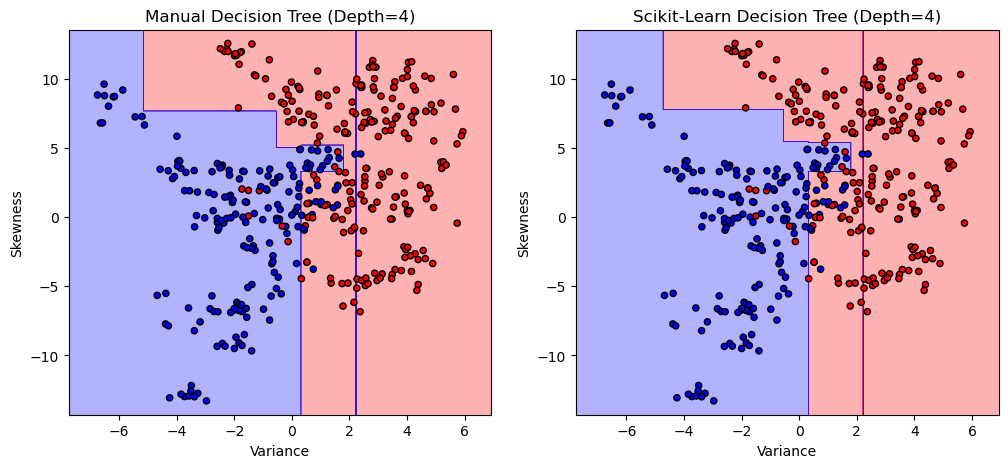

Manual Tree Structure (Depth=4):
[Feature 0 <= 0.318]
  [Feature 1 <= 7.658]
    [Feature 0 <= -0.550]
      [Feature 0 <= -1.786]
        Predict: 1
        Predict: 1
      [Feature 1 <= 5.010]
        Predict: 1
        Predict: 0
    [Feature 0 <= -5.166]
      Predict: 1
      Predict: 0
  [Feature 0 <= 1.788]
    [Feature 1 <= 5.202]
      [Feature 1 <= 3.296]
        Predict: 0
        Predict: 1
      Predict: 0
    [Feature 0 <= 2.228]
      [Feature 0 <= 2.212]
        Predict: 0
        Predict: 1
      Predict: 0


In [6]:
def plot_decision_boundary(X, y, model, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(('red', 'blue')))
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor='k', s=20, cmap=ListedColormap(('red', 'blue')))
    plt.xlabel('Variance')
    plt.ylabel('Skewness')
    plt.title(title)

# Train manual tree
dt_manual = DecisionTreeScratch(max_depth=4, criterion='gini')
dt_manual.fit(X_train_2d, y_train_2d)

# Train sklearn tree
dt_sklearn = DecisionTreeClassifier(max_depth=4, criterion='gini', random_state=42)
dt_sklearn.fit(X_train_2d, y_train_2d)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plot_decision_boundary(X_test_2d, y_test_2d, dt_manual, "Manual Decision Tree (Depth=4)")
plt.subplot(1, 2, 2)
plot_decision_boundary(X_test_2d, y_test_2d, dt_sklearn, "Scikit-Learn Decision Tree (Depth=4)")
plt.show()

print("Manual Tree Structure (Depth=4):")
dt_manual.print_tree()

### Part B - Linear SVM from Scratch Implementation

In [7]:
class LinearSVMScratch:
    def __init__(self, learning_rate=0.001, C=1.0, n_iters=1000):
        self.lr = learning_rate
        self.C = C
        self.n_iters = n_iters
        self.w = None
        self.b = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        # Map labels to -1 and 1
        y_ = np.where(y <= 0, -1, 1)
        
        self.w = np.zeros(n_features)
        self.b = 0

        # Subgradient descent
        for _ in range(self.n_iters):
            for idx, x_i in enumerate(X):
                condition = y_[idx] * (np.dot(x_i, self.w) - self.b) >= 1
                if condition:
                    # Point is outside margin or correctly classified, regularize weights
                    self.w -= self.lr * (self.w) # Using 1/C concept structurally, scaled by learning rate
                else:
                    # Point violates margin
                    self.w -= self.lr * (self.w - self.C * y_[idx] * x_i)
                    self.b -= self.lr * (self.C * y_[idx])

    def predict(self, X):
        approx = np.dot(X, self.w) - self.b
        return np.where(approx >= 0, 1, 0)
    
    def decision_function(self, X):
        return np.dot(X, self.w) - self.b

# Data Scaling (Important for SVM)
class StandardScalerScratch:
    def fit_transform(self, X):
        self.mean_ = np.mean(X, axis=0)
        self.scale_ = np.std(X, axis=0)
        return (X - self.mean_) / self.scale_
    def transform(self, X):
        return (X - self.mean_) / self.scale_

scaler_2d = StandardScalerScratch()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

### Part B - Linear SVM Training and Boundary Plotting

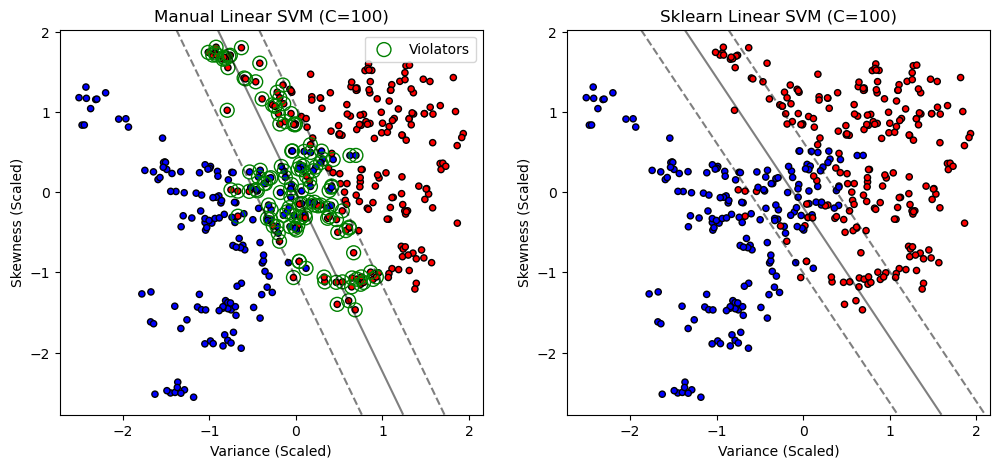

In [8]:
# Train manual SVM
svm_manual = LinearSVMScratch(learning_rate=0.001, C=100, n_iters=1000)
svm_manual.fit(X_train_2d_scaled, y_train_2d)

# Train sklearn SVM
svm_sklearn = SVC(kernel='linear', C=100, random_state=42)
svm_sklearn.fit(X_train_2d_scaled, y_train_2d)

def plot_svm_boundary(X, y, model, title, is_manual=False):
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor='k', s=20, cmap=ListedColormap(('red', 'blue')))
    ax = plt.gca()
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    
    xx = np.linspace(xlim[0], xlim[1], 30)
    yy = np.linspace(ylim[0], ylim[1], 30)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T
    
    Z = model.decision_function(xy).reshape(XX.shape)
    ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])
    
    if is_manual:
        # Highlight margin violators (y*(wx-b) < 1)
        y_ = np.where(y <= 0, -1, 1)
        dfunc = model.decision_function(X)
        violators = X[y_ * dfunc < 1]
        ax.scatter(violators[:, 0], violators[:, 1], s=100, linewidth=1, facecolors='none', edgecolors='green', label='Violators')
        plt.legend(loc='upper right')
        
    plt.title(title)
    plt.xlabel('Variance (Scaled)')
    plt.ylabel('Skewness (Scaled)')

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plot_svm_boundary(X_test_2d_scaled, y_test_2d, svm_manual, "Manual Linear SVM (C=100)", is_manual=True)
plt.subplot(1, 2, 2)
plot_svm_boundary(X_test_2d_scaled, y_test_2d, svm_sklearn, "Sklearn Linear SVM (C=100)")
plt.show()

### Part B - Hyperparameter Exploration (C, Learning Rate, Iterations)

In [11]:
# Study the effect of regularization (C), learning rate, and iterations
experiment_results = []

# Baseline parameters to test against
experiments = [
    # Testing the effect of Regularization (C)
    {"C": 0.01, "lr": 0.001, "iters": 1000, "Notes": "Low C (Wider margin, more violations)"},
    {"C": 1.0, "lr": 0.001, "iters": 1000, "Notes": "Medium C (Balanced)"},
    {"C": 100.0, "lr": 0.001, "iters": 1000, "Notes": "High C (Harder margin, fewer violations)"},
    
    # Testing the effect of Learning Rate
    {"C": 1.0, "lr": 0.0001, "iters": 1000, "Notes": "Low LR (Slower convergence)"},
    {"C": 1.0, "lr": 0.01, "iters": 1000, "Notes": "High LR (Faster, but may overshoot)"},
    
    # Testing the effect of Iterations
    {"C": 1.0, "lr": 0.001, "iters": 100, "Notes": "Low Iterations (Underfitting risk)"},
    {"C": 1.0, "lr": 0.001, "iters": 2000, "Notes": "High Iterations (Better convergence)"}
]

for exp in experiments:
    # Initialize and train the manual SVM
    test_svm = LinearSVMScratch(learning_rate=exp["lr"], C=exp["C"], n_iters=exp["iters"])
    test_svm.fit(X_train_2d_scaled, y_train_2d)
    
    # Predict and evaluate
    y_pred = test_svm.predict(X_test_2d_scaled)
    acc = accuracy_score(y_test_2d, y_pred)
    
    # Store results
    experiment_results.append({
        "C (Regularization)": exp["C"],
        "Learning Rate": exp["lr"],
        "Iterations": exp["iters"],
        "Accuracy": acc,
        "Observation": exp["Notes"]
    })

# Display results as a formatted DataFrame
hyperparam_df = pd.DataFrame(experiment_results)
display(hyperparam_df)

,C (Regularization),Learning Rate,Iterations,Accuracy,Observation
0,0.01,0.0010,1000,0.555825,"Low C (Wider margin, more violations)"
1,1.00,0.0010,1000,0.844660,Medium C (Balanced)
2,100.00,0.0010,1000,0.866505,"High C (Harder margin, fewer violations)"
3,1.00,0.0001,1000,0.844660,Low LR (Slower convergence)
4,1.00,0.0100,1000,0.851942,"High LR (Faster, but may overshoot)"
5,1.00,0.0010,100,0.844660,Low Iterations (Underfitting risk)
6,1.00,0.0010,2000,0.844660,High Iterations (Better convergence)


### Part C - Kernel SVM and Nonlinear Boundaries

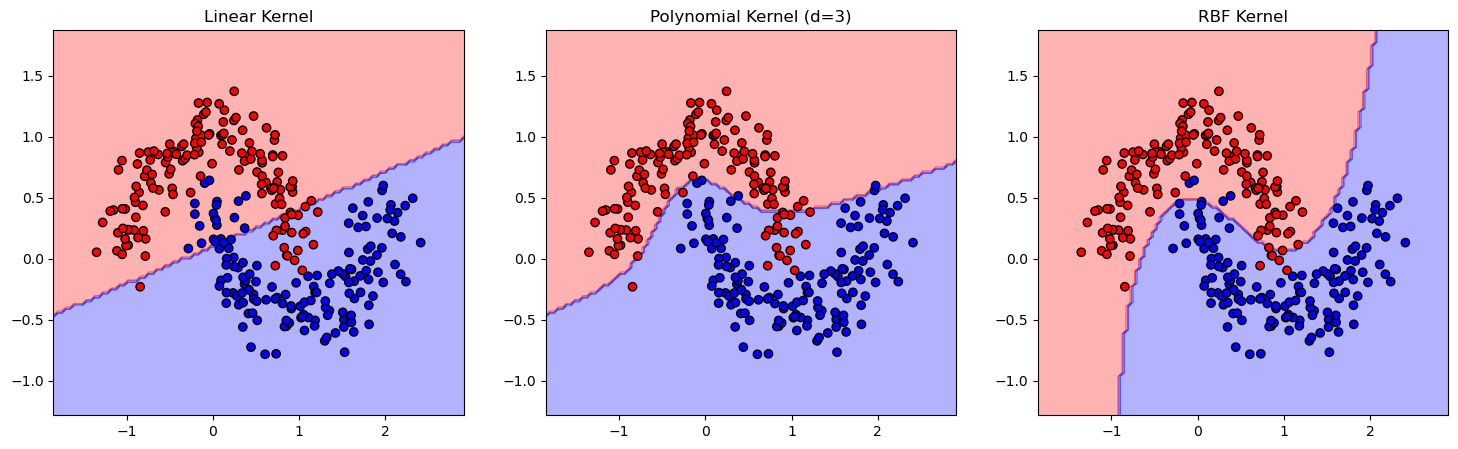

In [9]:
# Generate nonlinear dataset
X_moons, y_moons = make_moons(n_samples=300, noise=0.15, random_state=42)

svm_lin = SVC(kernel='linear', C=1)
svm_poly = SVC(kernel='poly', degree=3, C=1)
svm_rbf = SVC(kernel='rbf', gamma='auto', C=1)

models = [svm_lin, svm_poly, svm_rbf]
titles = ['Linear Kernel', 'Polynomial Kernel (d=3)', 'RBF Kernel']

plt.figure(figsize=(18, 5))
for i, (model, title) in enumerate(zip(models, titles)):
    model.fit(X_moons, y_moons)
    plt.subplot(1, 3, i + 1)
    
    xx, yy = np.meshgrid(np.linspace(X_moons[:, 0].min()-0.5, X_moons[:, 0].max()+0.5, 100),
                         np.linspace(X_moons[:, 1].min()-0.5, X_moons[:, 1].max()+0.5, 100))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(('red', 'blue')))
    plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, edgecolor='k', cmap=ListedColormap(('red', 'blue')))
    plt.title(title)
plt.show()

### Part D - Final Comparison (All 4 Features)

In [10]:
# Scale full dataset for SVMs
scaler_4d = StandardScalerScratch()
X_train_scaled = scaler_4d.fit_transform(X_train)
X_test_scaled = scaler_4d.transform(X_test)

# Initialize Models
models = {
    "Manual DT": DecisionTreeScratch(max_depth=5, criterion='gini'),
    "Sklearn DT": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Manual Lin SVM": LinearSVMScratch(learning_rate=0.001, C=100, n_iters=1000),
    "Sklearn Lin SVM": SVC(kernel='linear', C=100, random_state=42),
    "Sklearn RBF SVM": SVC(kernel='rbf', C=10, gamma='auto', random_state=42)
}

results = []

for name, model in models.items():
    # Choose appropriately scaled data
    X_tr = X_train_scaled if "SVM" in name else X_train
    X_te = X_test_scaled if "SVM" in name else X_test
    
    # Timing Training
    start_train = time.time()
    model.fit(X_tr, y_train)
    time_train = time.time() - start_train
    
    # Timing Prediction
    start_pred = time.time()
    y_pred = model.predict(X_te)
    time_pred = time.time() - start_pred
    
    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    results.append({
        "Model": name, "Accuracy": acc, "Precision": prec, 
        "Recall": rec, "F1-Score": f1, "Train Time(s)": time_train, "Pred Time(s)": time_pred
    })

# Print Results
results_df = pd.DataFrame(results).round(4)
display(results_df) # Use print(results_df) if not in Jupyter

,Model,Accuracy,Precision,Recall,F1-Score,Train Time(s),Pred Time(s)
0,Manual DT,0.9563,1.0000,0.9016,0.9483,1.4214,0.000
1,Sklearn DT,0.9636,1.0000,0.9180,0.9573,0.0065,0.000
2,Manual Lin SVM,0.9782,0.9579,0.9945,0.9759,4.4858,0.000
3,Sklearn Lin SVM,0.9879,0.9837,0.9891,0.9864,0.0164,0.000
4,Sklearn RBF SVM,1.0000,1.0000,1.0000,1.0000,0.0113,0.003


### Part D - Discussion

**Interpretability:** Decision Trees (especially the manual one) provide high interpretability through readable if-else feature rules. SVMs (especially with RBF kernels) operate as "black boxes" offering little intuitive transparency besides support vectors.

**Scaling Requirements:** SVMs strictly require feature scaling (StandardScaler) because they compute distances (margins). Large feature bounds distort the weight updates. Decision Trees require no scaling as splits are relative and rank-based.

**Model Complexity & Overfitting:** The manual DT can easily overfit if max_depth is unbounded. Regularizing SVM via C creates a soft margin to prevent overfitting against outliers. The RBF SVM captured complexity best but risks overfitting if gamma is set too high.

**Performance:** Scikit-learn's implementations are highly optimized (often written in C/Cython), completing training significantly faster than native nested loops in Python. RBF SVM generally yields the highest accuracy on nonlinear datasets like Banknote Authentication.